#  **Reading Dataset**

In [ ]:
import pandas as pd
import numpy as np
import re
import nltk

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
# Load Data
df_reviews = pd.read_csv('Amazon_Reviews.csv', engine='python', on_bad_lines='skip')

In [ ]:
rating_col = 'Rating'

df_reviews = df_reviews.dropna(subset=[rating_col]).copy() #drop missing/empty values

# convert string to numeric digit (eg: "Rated 1 out of 5 stars" -> 1)
df_reviews['numeric_rating'] = df_reviews[rating_col].str.extract(r'(\d+)').astype(int)

#print(df_reviews['numeric_rating'])

# Set 1-2 to negative, 3 to neutral and 4-5 to positive
def categorize_rating(rating):
    if rating >= 4:
        return 'positive'
    elif rating == 3:
        return 'neutral'
    else:
        return 'negative'

df_reviews['sentiment'] = df_reviews['numeric_rating'].apply(categorize_rating)

#print(df_reviews[[rating_col, 'numeric_rating', 'sentiment']].head(20))

In [ ]:
# Check total available reviews per sentiment
print(df_reviews['sentiment'].value_counts())

sentiment
negative    14350
positive     5820
neutral       885
Name: count, dtype: int64


In [ ]:
# Keep positive and negative reviews, drop neutral reviews
df_reviews_amazon = df_reviews[df_reviews['sentiment'].isin(['positive', 'negative'])].copy()

print(df_reviews_amazon['sentiment'].value_counts())

sentiment
negative    14350
positive     5820
Name: count, dtype: int64


# **Text Preprocessing**


In [ ]:
!pip install contractions

In [ ]:
import contractions
import re

In [ ]:
def clean_text(text):
  # Expand contractions (don't -> do not)
  text = contractions.fix(text, slang=False)

  # Lowercase
  text = text.lower()

  # Remove URL
  text = re.sub(r'https?://\S+|www\.\S+', '', text)

  # Remove HTML tags
  text = re.sub(r'<.*?>', ' ', text)

  # Remove emojis and special characters (keep only letters, numbers & spaces)
  text = re.sub(r'[^a-z0-9\s]', ' ', text)

  # Remove extra whitespace
  text = " ".join(text.split())

  return text


In [ ]:
df_reviews_amazon['Review Text'] = df_reviews_amazon['Review Text'].apply(clean_text)

# **Splitting Data into Train, Validation and Test Sets**

In [ ]:
# Import train_test_split
from sklearn.model_selection import train_test_split

## Split imbalanced dataframe (75% train, 10% validation, 15% test)
# 15% of the data for testing
train_val, test = train_test_split(df_reviews_amazon, test_size=0.15, random_state=42, stratify=df_reviews_amazon['sentiment'])

# Split the remaining data into training and validation sets: 75% training, 10% validation
train, val = train_test_split(train_val, test_size=0.10/0.85, random_state=42, stratify=train_val['sentiment'])

In [ ]:
train_x, train_y = train['Review Text'], train['sentiment']
val_x, val_y = val['Review Text'], val['sentiment']
test_x, test_y = test['Review Text'], test['sentiment']

In [ ]:
# Check the number of rows
print("Training:", len(train)) # 75% of data
print("Validation:", len(val)) # 10% of data
print("Test:", len(test)) # 15% of data

Training: 15127
Validation: 2017
Test: 3026


## **Balancing Traning Data with RandomUnderSampler** ##



<Axes: title={'center': 'Training Data Before Balancing'}, xlabel='sentiment'>

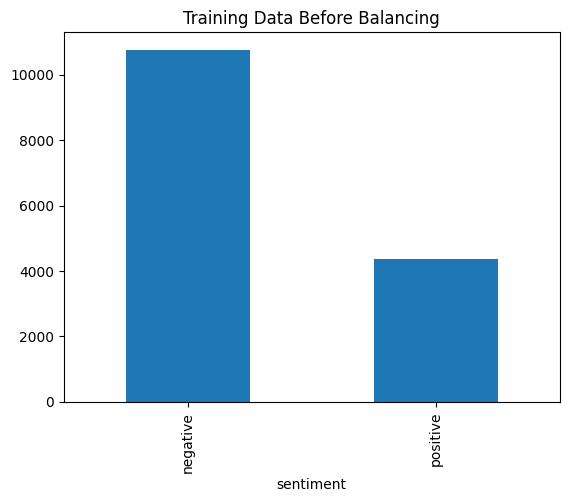

In [ ]:
# Data Distribution before balancing
train_y.value_counts().plot(kind='bar', title='Training Data Before Balancing')

In [ ]:
from imblearn.under_sampling import RandomUnderSampler

# Only balance the training set
rus = RandomUnderSampler(random_state=42)

train_x_balanced, train_y_balanced = rus.fit_resample(train_x.to_frame(), train_y)

train_x_balanced = train_x_balanced['Review Text']

print(train_y_balanced.value_counts())

sentiment
negative    4365
positive    4365
Name: count, dtype: int64


<Axes: title={'center': 'Training Data Before Balancing'}, xlabel='sentiment'>

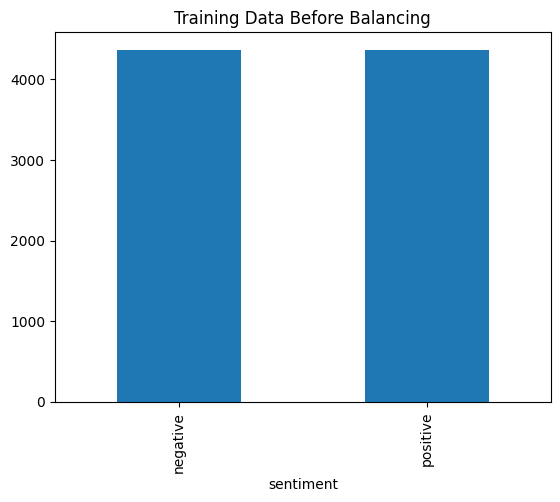

In [ ]:
# Data Distribution after balancing
train_y_balanced.value_counts().plot(kind='bar', title='Training Data Before Balancing')

# **Text Representation (Bag of Words)**
Fit TF-IDF on balanced training data (Transform Val/Test)

In [ ]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer

## 1. Custom stop words list
custom_stop_words = list(ENGLISH_STOP_WORDS)

# Remove these 4 words from the list because they can change the meaning of a review
# For example: This product is not good.
for word in ['not', 'no', 'never', 'nor']:
    if word in custom_stop_words:
        custom_stop_words.remove(word)

## 2. TF-IDF
tfidf = TfidfVectorizer(ngram_range=(1, 2), stop_words=custom_stop_words)
# ngram_range=(1,2): TF-IDF considers both unigrams (single words) & bigrams (pairs of words)
# CAN DELETE, Because we have words like "right shambles" & our model treated it as +ve review

# Fit TF-IDF using balanced training data
train_x_vector = tfidf.fit_transform(train_x_balanced)

# Transform validation and test reviews using the same TF-IDF
val_x_vector = tfidf.transform(val_x) # validation data
test_x_vector = tfidf.transform(test_x) # test data

# Number of reviews, number of features
print("Training:", train_x_vector.shape)
print("Validation:", val_x_vector.shape)
print("Test:", test_x_vector.shape)

Training: (8730, 180722)
Validation: (2017, 180722)
Test: (3026, 180722)


In [ ]:
# Convert TF-IDF Training data from a matrix into Pandas DataFrame, so it's easier to view & understand
pd.DataFrame.sparse.from_spmatrix(
    train_x_vector,
    index=train_x_balanced.index,
    columns=tfidf.get_feature_names_out()
)


,00,00 11,00 17,00 200,00 account,00 agent,00 amazon,00 amnics,00 amthen,00 applied,...,zuckerberg gates,zumimal,zumimal offered,zumimall,zumimall customer,zumimall wireless,zumzee,zumzee advertising,zy,zy cxnts
457,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2771,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3438,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9412,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
13780,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21202,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
14818,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7720,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
17792,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


# **Model Selection**

 Train models using the balanced, TF-IDF-transformed training data.



### **Support Vector Machines (SVM)**

In [ ]:
from sklearn.svm import SVC

svc = SVC(kernel='linear')
svc.fit(train_x_vector, train_y_balanced)

SVC(kernel='linear')

### **Logistic Regression** ###

In [ ]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(train_x_vector, train_y_balanced)

LogisticRegression(max_iter=1000)

### **Multinomial Naive Bayes** ###

In [ ]:
from sklearn.naive_bayes import MultinomialNB

nb = MultinomialNB()
nb.fit(train_x_vector, train_y_balanced)

MultinomialNB()

### **Random Forest** ###

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(train_x_vector, train_y_balanced)

RandomForestClassifier(random_state=42)

### **Decision Tree Classifier** ###

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dec_tree = DecisionTreeClassifier(random_state=42)
dec_tree.fit(train_x_vector, train_y_balanced)

DecisionTreeClassifier(random_state=42)

# **Model Evaluation**


### **Comparing Models - Classification report (Validation set)** ###

In [ ]:
from sklearn.metrics import classification_report

models = {
    'SVM': svc,
    'Logistic Regression': log_reg,
    'Naive Bayes': nb,
    'Random Forest': rf,
    'Decision Tree': dec_tree,
}

for name, model in models.items():
    val_predictions = model.predict(val_x_vector)

    print(f"\n--- {name} ---")
    print(classification_report(val_y, val_predictions))



--- SVM ---
              precision    recall  f1-score   support

    negative       0.97      0.96      0.96      1435
    positive       0.90      0.93      0.91       582

    accuracy                           0.95      2017
   macro avg       0.94      0.94      0.94      2017
weighted avg       0.95      0.95      0.95      2017


--- Logistic Regression ---
              precision    recall  f1-score   support

    negative       0.96      0.95      0.96      1435
    positive       0.89      0.91      0.90       582

    accuracy                           0.94      2017
   macro avg       0.93      0.93      0.93      2017
weighted avg       0.94      0.94      0.94      2017


--- Naive Bayes ---
              precision    recall  f1-score   support

    negative       0.94      0.98      0.96      1435
    positive       0.94      0.85      0.89       582

    accuracy                           0.94      2017
   macro avg       0.94      0.91      0.93      2017
weighted av

## **SVM Model**
Since SVM performs best, so we evaluate it using test data

### **SVM - F1 Score** ###

In [ ]:
from sklearn.metrics import f1_score

test_predictions = svc.predict(test_x_vector)

f1_score(test_y, test_predictions, labels=['negative', 'positive'], average=None)

array([0.96120386, 0.90828238])


### **SVM - Classification report**

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(test_y, test_predictions,labels=['negative', 'positive']))

              precision    recall  f1-score   support

    negative       0.97      0.95      0.96      2153
    positive       0.88      0.94      0.91       873

    accuracy                           0.95      3026
   macro avg       0.93      0.94      0.93      3026
weighted avg       0.95      0.95      0.95      3026



In [ ]:
# Example predictions on reviews using the selected SVC model
# Output should be positive:
print("----- Output should be positive -----")
print(svc.predict(tfidf.transform(["Many products and great prices! Decent speed in delivery. Will purchase from the again!"])))
print(svc.predict(tfidf.transform(["I ordered a knife on Amazon but it cames late and I don't need it anymore. Amazon refunded me without asking me to return it. Can't complain."])))
print(svc.predict(tfidf.transform(["Shopping on Amazon has been a mixed bag. The prices are generally good, but the quality of products can be hit or miss. Delivery times are average, and customer service is responsive but sometimes slow. Not bad, but not perfect either."])))

# Output should be negative:
print("----- Output should be negative -----")
print(svc.predict(tfidf.transform(["My bank card froze only with amazon so couldn't order anything.Package said delivered at the post office when it hasn't been.Spoke to customer services about my card and he was very short with me and patronising when he was telling me how to take my bank card off then re add it. "])))
print(svc.predict(tfidf.transform(["This product is not good and I do not recommend it."])))
print(svc.predict(tfidf.transform(["Why do I say “don’t buy from Amazon”? On July 25th I ordered from Amazon UK a German electric razor. I got an email from Ninth Avenue taking the money and saying I could monitor the order at an R.R.Donnelley number. There was no info at this number. In August I complained that no razor had been delivered. They apologised for this “inconvenience”. Later I got a US mailed sealed envelope with an empty razor case. They ignored when I emailed this fact. They said the goods had been sent from a US warehouse and I should ask the local post and tell them the results. I told them I would be laughed out of it if I asked what happened to goods sent from an unknown US depot on a date unknown. I asked many times for my money back. I am still asking. Their ‘support service’ Headrush emailed that they had now satisfied my query which they were closing. As of 15 November I have received no razor and no money."])))
print(svc.predict(tfidf.transform(["Looks good but to be honest pretty terrible. The delivery time is terrible and the price is way too expensive. Ebay is way better."])))
print(svc.predict(tfidf.transform(["Diff to contact / cant solve simplest of issues"])))

----- Output should be positive -----
['positive']
['positive']
['positive']
----- Output should be negative -----
['negative']
['negative']
['negative']
['negative']
['negative']


# **EXTRA Model - Deep Learning Model - DistilBERT Model**
train_tockenized, validation_tockenized & test_tockenized

In [ ]:
# Compatibility workaround for this environment
import numpy as np

if not hasattr(np, "long"):
    np.long = np.int_

# Import libraries
import pandas as pd
import torch

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    DistilBertForSequenceClassification,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [ ]:
## 1. Convert sentiment to binary values
label_map = {"negative": 0, "positive": 1}

# Organize reviews and labels
train_ds = Dataset.from_dict({
    "text": train_x_balanced.astype(str).tolist(),
    "labels": pd.Series(train_y_balanced).map(label_map).tolist()
})

val_ds = Dataset.from_dict({
    "text": val_x.astype(str).tolist(),
    "labels": val_y.map(label_map).tolist()
})

test_ds = Dataset.from_dict({
    "text": test_x.astype(str).tolist(),
    "labels": test_y.map(label_map).tolist()
})

print("Training reviews:", len(train_ds))
print("Validation reviews:", len(val_ds))
print("Test reviews:", len(test_ds))

## 2. Load DistilBERT tokenizer
model_name = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

## 3. Tokenize the reviews
def tokenize_func(examples):
    return tokenizer(examples["text"], truncation=True, max_length=512)

train_tokenized = train_ds.map(tokenize_func, batched=True, remove_columns=["text"])
val_tokenized = val_ds.map(tokenize_func, batched=True, remove_columns=["text"])
test_tokenized = test_ds.map(tokenize_func, batched=True, remove_columns=["text"])

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

print("Tokenization completed!")

## 4. Load the pre-trained DistilBERT model
id2label = {0: "negative", 1: "positive"}
label2id = {"negative": 0, "positive": 1}

bert_model = DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2, # Have 2 labels: positive(1) and negative(0)
    id2label=id2label,
    label2id=label2id
)

## 5. Define evaluation metrics
def compute_metrics(eval_pred):
    logits, labels = eval_pred # receives the evaluation results
    predictions = np.argmax(logits, axis=1) # select the class with the highest score for each review

    return {"accuracy": accuracy_score(labels, predictions), "f1_macro": f1_score(labels, predictions, average="macro")}

## 6. Set the training parameters
training_args = TrainingArguments(
    output_dir="./distilbert_amazon",
    eval_strategy="epoch", # evaluate after every epoch
    save_strategy="epoch", # save a checkpoint after every epoch
    load_best_model_at_end=True, # tell the Trainer to load the best checkpoint after training finishes
    metric_for_best_model="f1_macro",
    learning_rate=2e-5,
    per_device_train_batch_size=8, # model processes 8 reviews per training batch
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    report_to="none",
    seed=42,
    dataloader_num_workers=0
)

## 7. Create the Trainer
trainer = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=val_tokenized,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

## 8. Train DistilBERT
print("Starting DistilBERT training...")
trainer.train()

## 9. Evaluate DistilBERT on the validation set
val_predictions = trainer.predict(val_tokenized)

bert_val_preds = np.argmax(val_predictions.predictions, axis=1)
y_val_num = val_predictions.label_ids

print("\n--- DistilBERT Validation Results ---")
print("\nValidation Classification Report:")
print(classification_report(
    y_val_num,
    bert_val_preds,
    labels=[0, 1],
    target_names=["negative", "positive"],
    zero_division=0
))


Training reviews: 8730
Validation reviews: 2017
Test reviews: 3026


Map:   0%|          | 0/8730 [00:00<?, ? examples/s]

Map:   0%|          | 0/2017 [00:00<?, ? examples/s]

Map:   0%|          | 0/3026 [00:00<?, ? examples/s]

Tokenization completed!


...

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.193989,0.133226,0.960337,0.952275
2,0.100562,0.181790,0.954883,0.946708
3,0.068535,0.169759,0.961824,0.954354


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


--- DistilBERT Validation Results ---

Validation Classification Report:
              precision    recall  f1-score   support

    negative       0.99      0.96      0.97      1435
    positive       0.91      0.97      0.94       582

    accuracy                           0.96      2017
   macro avg       0.95      0.96      0.95      2017
weighted avg       0.96      0.96      0.96      2017



In [ ]:
# Example predictions on reviews using the selected SVC model
# Output should be positive:
from transformers import pipeline

sentiment_pipeline = pipeline("text-classification", model=trainer.model, tokenizer=tokenizer)

# Output should be positive:
print("----- Output should be positive -----")
print(sentiment_pipeline(["Many products and great prices! Decent speed in delivery. Will purchase from the again!"])[0]["label"])
print(sentiment_pipeline(["I ordered a knife on Amazon but it cames late and I don't need it anymore. Amazon refunded me without asking me to return it. Can't complain."])[0]["label"])
print(sentiment_pipeline(["Shopping on Amazon has been a mixed bag. The prices are generally good, but the quality of products can be hit or miss. Delivery times are average, and customer service is responsive but sometimes slow. Not bad, but not perfect either."])[0]["label"])

# Output should be negative:
print("----- Output should be negative -----")
print(sentiment_pipeline(["My bank card froze only with amazon so couldn't order anything.Package said delivered at the post office when it hasn't been.Spoke to customer services about my card and he was very short with me and patronising when he was telling me how to take my bank card off then re add it. "])[0]["label"])
print(sentiment_pipeline(["This product is not good and I do not recommend it."])[0]["label"])
print(sentiment_pipeline(["Why do I say “don’t buy from Amazon”? On July 25th I ordered from Amazon UK a German electric razor. I got an email from Ninth Avenue taking the money and saying I could monitor the order at an R.R.Donnelley number. There was no info at this number. In August I complained that no razor had been delivered. They apologised for this “inconvenience”. Later I got a US mailed sealed envelope with an empty razor case. They ignored when I emailed this fact. They said the goods had been sent from a US warehouse and I should ask the local post and tell them the results. I told them I would be laughed out of it if I asked what happened to goods sent from an unknown US depot on a date unknown. I asked many times for my money back. I am still asking. Their ‘support service’ Headrush emailed that they had now satisfied my query which they were closing. As of 15 November I have received no razor and no money."])[0]["label"])
print(sentiment_pipeline(["Looks good but to be honest pretty terrible. The delivery time is terrible and the price is way too expensive. Ebay is way better."])[0]["label"])
print(sentiment_pipeline(["Diff to contact / cant solve simplest of issues"])[0]["label"])

----- Output should be positive -----
positive
positive
positive
----- Output should be negative -----
positive
positive
negative
negative
positive


### **DistilBERT - F1 Score** ###

In [ ]:
from sklearn.metrics import f1_score

test_predictions = trainer.predict(test_tokenized)

bert_test_preds = np.argmax(test_predictions.predictions, axis=1)
y_test_num = test_predictions.label_ids

f1_score(y_test_num, bert_test_preds, labels=[0, 1], average=None)

array([0.9658606, 0.9214831])

### **DistilBERT - Classification Report** ###

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test_num, bert_test_preds, labels=[0, 1], target_names=["negative", "positive"], zero_division=0))

              precision    recall  f1-score   support

    negative       0.99      0.95      0.97      2153
    positive       0.88      0.97      0.92       873

    accuracy                           0.95      3026
   macro avg       0.93      0.96      0.94      3026
weighted avg       0.96      0.95      0.95      3026

